# Hardware cost, noise, and position in the literature
Point 3: what the constraint-native ansatz **costs** once compiled for a real IBM Heron device (FakeMarrakesh, 156 qubits, heavy-hex, CZ basis), and whether its advantage survives that device's noise model. Point 4: what is already known and what this repository adds.

Circuits (`qps_circuits.py`) are verified against the exact simulator in `qps_lib.py`: the Dicke-state circuit (Bärtschi & Eidenbenz split-and-cyclic-shift) reproduces |D(n,k)⟩ exactly, and both QAOA circuits reproduce the simulator's output distribution to 10⁻¹⁵. Results are produced by `hardware_sim.py` (≈3 min) and loaded here. The penalty baseline is `pen_tight`, the strongest penalty variant in the robustness scan.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
g=pd.read_csv('results/gatecounts.csv'); d=pd.read_csv('results/noisy.csv')
t=g.groupby(['n','p','method'])[['twoq','depth']].mean().unstack().round(0); display(t)
r=(t['twoq']['xy_dicke']/t['twoq']['pen_tight']).round(2); print('2-qubit gate ratio XY/penalty:'); print(r.unstack())

twoq              depth         
method pen_tight xy_dicke pen_tight xy_dicke
n  p                                        
8  1        94.0    343.0      65.0    264.0
   2       211.0    488.0     124.0    362.0
   3       315.0    621.0     175.0    437.0
12 1       234.0    837.0     114.0    602.0
   2       516.0   1116.0     206.0    705.0
   3       798.0   1389.0     325.0    767.0
16 1       424.0   1509.0     175.0    968.0
   2       811.0   2033.0     251.0   1178.0
   3      1198.0   2571.0     353.0   1341.0

2-qubit gate ratio XY/penalty:
p      1     2     3
n                   
8   3.65  2.31  1.97
12  3.58  2.16  1.74
16  3.56  2.51  2.15


**Reading.** Both ansätze pay for the same dense cost layer (all-pairs ZZ, because the covariance matrix is dense). The XY ring adds n XX+YY gates per layer, a small amount. Most of the extra cost is the **Dicke-state preparation**, done once: its doubly-controlled RY gates decompose into many CZs plus SWAPs on heavy-hex. So the XY ansatz needs ≈3.6× the 2-qubit gates at p = 1 and ≈2× at p = 3. The gap narrows with p, because the preparation is paid only once.

## Noisy simulation (n = 8, k = 3, 11 months, parameters trained noiselessly, 8192 shots, FakeMarrakesh noise model)

twoq  p_feas  enhancement  enh_postselected  \
p method    sim                                                       
1 pen_tight noiseless   91.0   0.499        1.889             4.141   
            noisy       91.0   0.459        1.597             3.766   
  xy_dicke  noiseless  340.0   1.000        5.982             5.982   
            noisy      340.0   0.547        2.529             4.618   
2 pen_tight noiseless  204.0   0.611        4.237             6.854   
            noisy      204.0   0.477        2.504             5.209   
  xy_dicke  noiseless  493.0   1.000        9.308             9.308   
            noisy      493.0   0.395        1.850             4.688   

                       ratio_cond  
p method    sim                    
1 pen_tight noiseless       0.641  
            noisy           0.636  
  xy_dicke  noiseless       0.760  
            noisy           0.711  
2 pen_tight noiseless       0.664  
            noisy           0.647  
  xy_dicke  noiseless       0.803  
            noisy           0.684

p=1: noisy + postselection, XY better in 73% of months
p=2: noisy + postselection, XY better in 73% of months


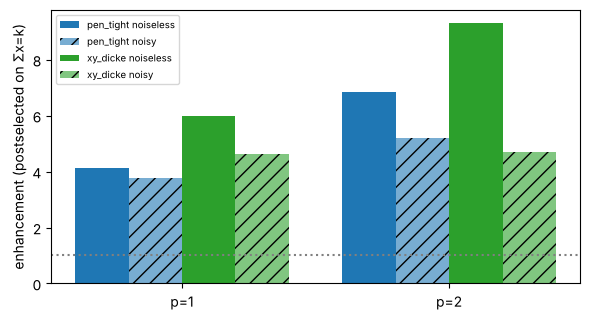

In [2]:
d['enh_postselected']=d.enhancement/d.p_feas
s=d.groupby(['p','method','sim'])[['twoq','p_feas','enhancement','enh_postselected','ratio_cond']].mean().round(3); display(s)
for p in [1,2]:
    x=d[(d.p==p)&(d.sim=='noisy')].pivot(index='month',columns='method',values='enh_postselected')
    print(f'p={p}: noisy + postselection, XY better in {(x.xy_dicke>x.pen_tight).mean():.0%} of months')
fig,ax=plt.subplots(figsize=(6,3.3)); w=0.2
for i,(m,sim) in enumerate([('pen_tight','noiseless'),('pen_tight','noisy'),('xy_dicke','noiseless'),('xy_dicke','noisy')]):
    v=[s.loc[(p,m,sim),'enh_postselected'] for p in [1,2]]
    ax.bar(np.arange(2)+(i-1.5)*w,v,w,label=f'{m} {sim}',hatch='//' if sim=='noisy' else None,color='C2' if m=='xy_dicke' else 'C0',alpha=.6 if sim=='noisy' else 1)
ax.axhline(1,ls=':',color='gray'); ax.set_xticks([0,1]); ax.set_xticklabels(['p=1','p=2']); ax.set_ylabel('enhancement (postselected on Σx=k)')
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig('results/noisy.png',dpi=130)

**What this shows, honestly.**
* Noise destroys the XY ansatz's main structural advantage: noiselessly p(feasible) = 1, under the device noise model only ≈ 0.4–0.55, no better than penalty QAOA.
* Since a valid portfolio has exactly k ones, infeasible shots can be **discarded for free** (postselection). With postselection the XY ansatz still wins at p = 1 (≈4.6× vs 3.8× over random, better in 73% of months). At p = 2 the mean gain disappears (4.7× vs 5.2×) even though XY is still better in 73% of months, so a few months dominate the penalty mean. The extra ~300 CZs eat most of the noiseless advantage (9.3× → 4.7×).
* So the noiseless conclusion ("put the constraint in the mixer") holds on current hardware **only if the state preparation is cheap**. That points to concrete next steps: cheaper Dicke preparation, or Dicke-free starts with a short warm-up; error mitigation; hardware-aware XY layouts that match the heavy-hex coupling map.
* Limits: one device model, n = 8 only (noisy density simulation above that is out of reach here), parameters not re-trained under noise.

# Position in the literature
| Work | What it does | Relation to this repository |
|---|---|---|
| Hadfield et al., *Algorithms* 12, 34 (2019), [arXiv:1709.03489](https://arxiv.org/abs/1709.03489) | Quantum Alternating Operator Ansatz: constraint-preserving mixers | The XY-ring/Dicke construction used here |
| Wang, Rubin, Dominy, Rieffel, *PRA* 101, 012320 (2020), [arXiv:1904.09314](https://arxiv.org/abs/1904.09314) | Ring vs complete XY mixers, analytical and numerical | Our mixer choice; graph problems, not finance |
| Bärtschi & Eidenbenz, FCT 2019, [arXiv:1904.07358](https://arxiv.org/abs/1904.07358) | Deterministic Dicke-state preparation | Our Dicke circuit; its compiled cost is what limits us under noise |
| Hodson et al., [arXiv:1911.05296](https://arxiv.org/abs/1911.05296) (Rigetti) | Portfolio rebalancing with QAOA and XY-type mixers | Closest prior work: few synthetic/short-history instances, no paired statistics over many months |
| Brandhofer et al., *Quantum Inf. Process.* (2023), [arXiv:2207.10555](https://arxiv.org/abs/2207.10555) | Benchmarks portfolio QAOA (penalty formulation) incl. IBM hardware | Penalty-QAOA baseline behaviour; we add the constraint-native comparison at scale |
| He et al., *npj Quantum Inf.* (2023), [arXiv:2305.03857](https://arxiv.org/abs/2305.03857) | Initial state must be aligned with the mixer for constrained QAOA | Explains our basis-start vs Dicke-start gap (Part 1) |
| Egger et al. (incl. Woerner), *IEEE TQE* (2020), [arXiv:2006.14510](https://arxiv.org/abs/2006.14510); Herman et al., *Nat. Rev. Phys.* (2023), [arXiv:2201.02773](https://arxiv.org/abs/2201.02773) | Surveys of quantum computing for finance | Context; both stress that no practical advantage has been shown |

**What this repository adds** (no claim of quantum advantage; exact simulation up to 16 qubits):
1. Penalty vs constraint-native QAOA on **139 real monthly instances** of the same market (Euro Stoxx 50, 2015–2026), with bootstrap CIs and paired Wilcoxon tests instead of a handful of instances.
2. The gap **grows with problem size** (≈8× at n = 8 to ≈56× at n = 16, ratio of enhancements over random). It is robust to risk aversion, estimation window and a 64× penalty scan, and qiskit's own automatic penalty is the weakest choice.
3. With **several simultaneous constraints** (sectors, asset classes), penalty QAOA can fall **below random guessing**, while per-group XY rings keep improving.
4. Parameters **transfer** month to month (same quality at ~12% of the evaluations).
5. Under a realistic IBM noise model the advantage survives only with postselection and shallow depth, because Dicke preparation dominates the 2-qubit-gate count. This is a negative result, and it identifies a concrete bottleneck.